# Chapter 12 — Cross-Validation and Model Evaluation Techniques

**Book:** scikit-learn Cookbook, Third Edition — John Sukup (Packt Publishing, 2025)

This notebook follows the chapter sequence and demonstrates the core methods through executable examples. Numerical results appear immediately below the code, followed by a discussion of how to read them. The code examples are self-contained educational reproductions and extensions, not a word-for-word transcription of the text.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
np.set_printoptions(precision=3, suppress=True)
RANDOM_STATE=42

## 1. 1. Holdout validation

A train/test split separates model development from the final evaluation. Stratification preserves class proportions when drawing the split.

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
X,y=load_breast_cancer(return_X_y=True)
A,B,c,d=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)).fit(A,c)
print('Train accuracy:',round(model.score(A,c),3))
print('Test accuracy:',round(model.score(B,d),3))

Train accuracy: 0.988
Test accuracy: 0.986


**Interpretation.** Held-out accuracy is more informative than training accuracy alone because the model has not fitted those labels. One split can still be affected by sampling variability.

## 2. 2. K-fold cross-validation

K-fold cross-validation rotates the validation fold to give every observation a turn outside the training subset.

In [3]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
s=cross_val_score(make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),X,y,cv=cv,scoring='accuracy')
print('Fold scores:',s.round(3))
print('Mean:',round(s.mean(),3),'Std:',round(s.std(),3))

Fold scores: [0.974 0.947 0.965 0.991 0.991]
Mean: 0.974 Std: 0.017


**Interpretation.** The mean combines five held-out evaluations and the standard deviation describes their variation. Preprocessing belongs inside the pipeline so that each fold fits its own scaler.

## 3. 3. Comparing evaluation metrics

Accuracy can conceal uneven performance on different classes. Precision, recall, F1, and confusion matrices give complementary views.

In [4]:
from sklearn.metrics import confusion_matrix, classification_report
pred=model.predict(B)
print('Confusion matrix:')
print(confusion_matrix(d,pred))
print(classification_report(d,pred,target_names=load_breast_cancer().target_names))

Confusion matrix:
[[52  1]
 [ 1 89]]
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



**Interpretation.** The confusion matrix separates false positives from false negatives. The classification report helps determine whether both classes are recognized rather than relying on a single total accuracy.

## 4. 4. Hyperparameter search

GridSearchCV performs candidate selection using cross-validation and refits the winning configuration on the training data.

In [5]:
from sklearn.model_selection import GridSearchCV
pipeline=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))
search=GridSearchCV(pipeline,{'logisticregression__C':[.01,.1,1,10]},cv=4,scoring='f1')
search.fit(A,c)
print('Best C:',search.best_params_)
print('Best CV F1:',round(search.best_score_,3))
print('Held-out F1:',round(search.score(B,d),3))

Best C: {'logisticregression__C': 1}
Best CV F1: 0.983
Held-out F1: 0.989


**Interpretation.** The selected C is based only on folds drawn from training data. GridSearchCV.score uses the chosen refit model and the requested scoring method, so its final value here is F1 rather than accuracy.

## 5. 5. Learning curves

Learning curves compare training and validation scores as more training observations become available. They can reveal whether additional data might help.

In [6]:
from sklearn.model_selection import learning_curve
sizes,training,validation=learning_curve(make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),X,y,train_sizes=[.2,.4,.6,.8,1.],cv=4,scoring='accuracy')
for n,tr,va in zip(sizes,training.mean(axis=1),validation.mean(axis=1)):
    print('n=',n,'train=',round(tr,3),'CV=',round(va,3))

n= 85 train= 0.988 CV= 0.93
n= 170 train= 0.984 CV= 0.953
n= 255 train= 0.986 CV= 0.968
n= 340 train= 0.985 CV= 0.974
n= 426 train= 0.989 CV= 0.977


**Interpretation.** A substantial gap between training and validation can indicate overfitting. Curves that converge to a disappointing score may point toward underfitting or limited predictive features.

## 6. 6. Nested cross-validation

Nested cross-validation separates tuning from assessment: an inner loop selects parameters and an outer loop estimates model performance.

In [7]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
outer=StratifiedKFold(n_splits=3,shuffle=True,random_state=7)
inner_search=GridSearchCV(make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),{'logisticregression__C':[.1,1,10]},cv=3)
results=cross_val_score(inner_search,X,y,cv=outer,scoring='accuracy')
print('Outer-fold accuracy:',results.round(3))
print('Mean outer score:',round(results.mean(),3))

Outer-fold accuracy: [0.984 0.953 0.979]
Mean outer score: 0.972


**Interpretation.** Each outer test fold remains unseen during the inner parameter search. This gives a less optimistic assessment than evaluating many tuned choices on the same holdout repeatedly.

## 7. Holdout validation

A train-test split estimates performance on observations not seen during model fitting.

In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
D=load_breast_cancer();A,B,ya,yb=train_test_split(D.data,D.target,test_size=.25,stratify=D.target,random_state=42)
m=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000)).fit(A,ya)
print('Holdout accuracy:',round(m.score(B,yb),3))

Holdout accuracy: 0.986


**Interpretation.** The test set acts as an independent evaluation sample. Feature scaling is fitted inside the pipeline on training data only, reducing leakage risk.

## 8. K-fold cross-validation

K-fold validation rotates which subset is used for evaluation, yielding several performance estimates.

In [9]:
model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
acc=cross_val_score(model,D.data,D.target,cv=cv,scoring='accuracy')
print('Fold accuracies:',acc.round(3),'mean:',round(acc.mean(),3))

Fold accuracies: [0.974 0.947 0.965 0.991 0.991] mean: 0.974


**Interpretation.** The distribution across folds provides a first look at sensitivity to the partition. The mean alone does not capture all evaluation uncertainty.

## 9. Repeated stratified folds

Repeated splits expose the model to multiple train-test partitions rather than relying on one shuffled five-fold run.

In [10]:
from sklearn.model_selection import RepeatedStratifiedKFold
rcv=RepeatedStratifiedKFold(n_splits=4,n_repeats=2,random_state=42)
s=cross_val_score(model,D.data,D.target,cv=rcv,scoring='roc_auc')
print('AUC:',s.round(3),'mean:',round(s.mean(),3),'std:',round(s.std(),3))

AUC: [0.997 0.987 0.997 0.999 0.995 1.    0.983 0.997] mean: 0.994 std: 0.006


**Interpretation.** Variation across repeated folds reveals some sensitivity to sample composition. Repeated cross-validation is not equivalent to receiving new independently collected data.

## 10. Classification accuracy versus class imbalance

Accuracy alone can be misleading if nearly all observations belong to one class.

In [11]:
from sklearn.metrics import accuracy_score,balanced_accuracy_score
truth=np.array([0]*95+[1]*5);pred=np.zeros(100,dtype=int)
print('Accuracy:',accuracy_score(truth,pred),'Balanced accuracy:',balanced_accuracy_score(truth,pred))

Accuracy: 0.95 Balanced accuracy: 0.5


**Interpretation.** A classifier predicting the majority label every time can achieve impressive accuracy while completely missing the minority class. Balanced accuracy exposes this issue.

## 11. Precision, recall and F1-score

Precision describes the reliability of predicted positives, whereas recall measures how many actual positives are recovered.

In [12]:
from sklearn.metrics import precision_recall_fscore_support
from sklearn.model_selection import cross_val_predict
pred=cross_val_predict(model,D.data,D.target,cv=cv)
p,r,f,_=precision_recall_fscore_support(D.target,pred,average='binary')
print('Precision:',round(p,3),'Recall:',round(r,3),'F1:',round(f,3))

Precision: 0.967 Recall: 0.992 F1: 0.979


**Interpretation.** The F1-score balances precision and recall. In high-stakes situations, which metric deserves emphasis depends on the consequences of missed positives and false alarms.

## 12. Confusion matrix visualization

A confusion matrix gives the raw counts behind accuracy, precision and recall.

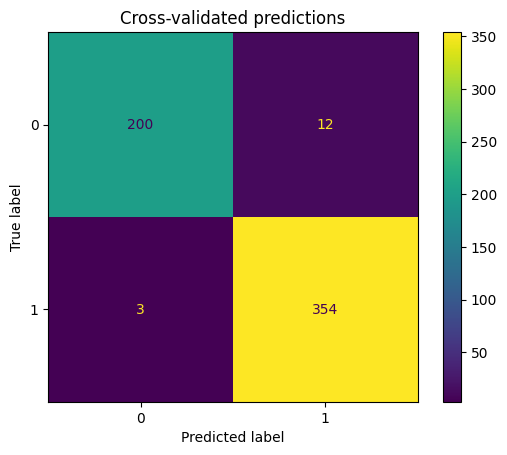

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(D.target,pred);plt.title('Cross-validated predictions');plt.show()

**Interpretation.** The diagonal records correct predictions and off-diagonal cells show specific mistakes. Counts should be interpreted against class prevalence.

## 13. ROC curve and AUC

A ROC curve compares true-positive rate with false-positive rate over a range of classification thresholds.

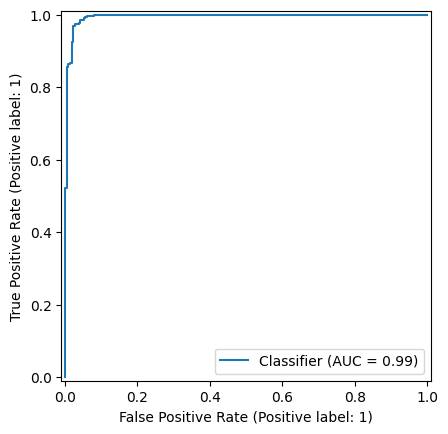

In [14]:
from sklearn.metrics import RocCurveDisplay
probs=cross_val_predict(model,D.data,D.target,cv=cv,method='predict_proba')[:,1]
RocCurveDisplay.from_predictions(D.target,probs);plt.show()

**Interpretation.** The curve summarizes the discrimination-threshold tradeoff. ROC-AUC is threshold-independent but does not guarantee well-calibrated probabilities.

## 14. Precision-recall curve

A precision-recall curve is often informative for rare-positive detection because it focuses on performance among positive predictions.

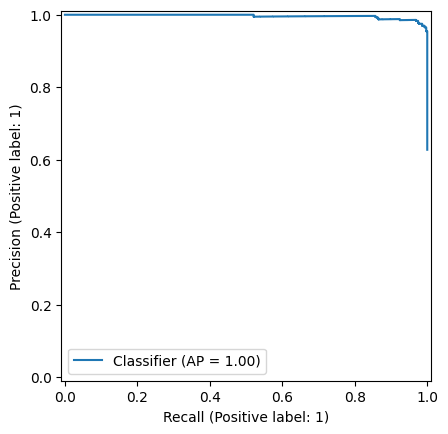

In [15]:
from sklearn.metrics import PrecisionRecallDisplay
PrecisionRecallDisplay.from_predictions(D.target,probs);plt.show()

**Interpretation.** A favorable curve maintains precision as recall increases. Its baseline depends on the prevalence of the positive class.

## 15. Cross-validating multiple metrics

Using a dictionary of scoring metrics prevents a single summary score from hiding different weaknesses.

In [16]:
from sklearn.model_selection import cross_validate
res=cross_validate(model,D.data,D.target,cv=cv,scoring={'accuracy':'accuracy','auc':'roc_auc','f1':'f1'})
for k,v in res.items():
 if k.startswith('test_'):print(k,round(v.mean(),3))

test_accuracy 0.974
test_auc 0.995
test_f1 0.979


**Interpretation.** A model can score differently depending on the metric; the best metric must be chosen based on the application, not only the highest numerical value.

## 16. Hyperparameter search with GridSearchCV

Grid search fits multiple candidate models through cross-validation and selects the highest-scoring configuration.

In [17]:
grid=GridSearchCV(model,{'logisticregression__C':[.01,.1,1,10]},cv=3,scoring='roc_auc')
grid.fit(A,ya);print('Best parameters:',grid.best_params_,'CV AUC:',round(grid.best_score_,3))

Best parameters: {'logisticregression__C': 0.1} CV AUC: 0.993


**Interpretation.** The chosen C reflects the search space and the training-fold results. Evaluation of the selected model should still use independent held-out data.

## 17. Randomized hyperparameter search

Randomized search samples configurations from a distribution and can be economical for a larger parameter space.

In [18]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform
rs=RandomizedSearchCV(model,{'logisticregression__C':loguniform(1e-3,1e2)},n_iter=8,random_state=42,cv=3,scoring='roc_auc').fit(A,ya)
print('Selected C:',round(rs.best_params_['logisticregression__C'],4),'CV AUC:',round(rs.best_score_,3))

Selected C: 0.0746 CV AUC: 0.993


**Interpretation.** Unlike a fixed grid, randomized search explores the scale of C stochastically. The sampling distribution determines which regions receive attention.

## 18. Learning curves and training sample size

A learning curve compares training and validation performance as more observations are available to fit the model.

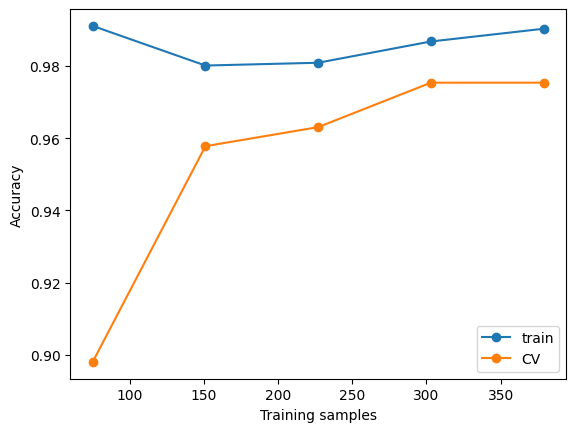

In [19]:
from sklearn.model_selection import learning_curve
sizes,tr,va=learning_curve(model,D.data,D.target,train_sizes=[.2,.4,.6,.8,1],cv=3,scoring='accuracy')
plt.plot(sizes,tr.mean(axis=1),'o-',label='train');plt.plot(sizes,va.mean(axis=1),'o-',label='CV');plt.legend();plt.xlabel('Training samples');plt.ylabel('Accuracy');plt.show()

**Interpretation.** A persistent train-validation gap indicates potential overfitting. Both curves converging at poor performance can suggest underfitting or inadequate features.

## 19. Validation curve and model complexity

Validation curves vary one hyperparameter and show whether the model is too constrained or too flexible.

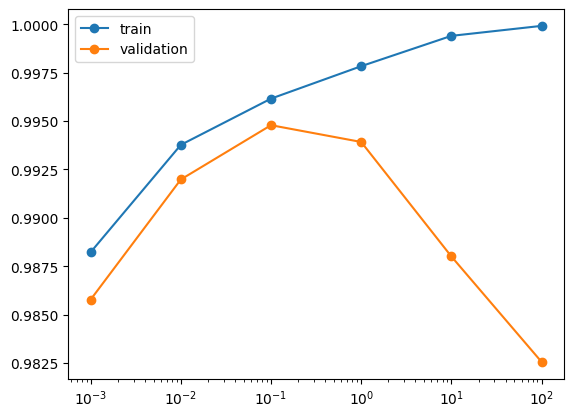

In [20]:
from sklearn.model_selection import validation_curve
cvals=[.001,.01,.1,1,10,100]
tr,va=validation_curve(model,D.data,D.target,param_name='logisticregression__C',param_range=cvals,cv=3,scoring='roc_auc')
plt.semilogx(cvals,tr.mean(axis=1),'o-',label='train');plt.semilogx(cvals,va.mean(axis=1),'o-',label='validation');plt.legend();plt.show()

**Interpretation.** The preferred region is where validation performance is strong and stable, rather than the maximum training score.

## 20. Nested cross-validation

Nested CV separates hyperparameter selection in inner folds from performance measurement in outer folds.

In [21]:
inner=GridSearchCV(model,{'logisticregression__C':[.01,.1,1,10]},cv=3,scoring='roc_auc')
outer=cross_val_score(inner,D.data,D.target,cv=3,scoring='roc_auc')
print('Nested CV scores:',outer.round(3),'mean:',round(outer.mean(),3))

Nested CV scores: [0.995 0.998 0.991] mean: 0.994


**Interpretation.** Evaluating a search procedure on outside folds avoids reporting its own optimized inner-CV score as an unbiased generalization estimate.